# 03 · Experimento sin recorte — Dropout 0.3 (CCSN)

**Objetivo:** entrenar una nueva CNN sobre las imágenes originales ya preparadas en `data/processed` (**sin recorte inferior**), con BatchNorm y dropout `p=0.3`. Se mantienen los splits originales y se reserva `test` para una evaluación final posterior.

**Primera ejecución:** este cuaderno entrena una vez al ejecutar su celda de entrenamiento; no recupera resultados de otro run ni sobrescribe checkpoints existentes. Ejecuta las celdas de arriba abajo.

## 1. Importaciones y raíz del proyecto

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torchvision.datasets import ImageFolder

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "clouds_cnn").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src" / "clouds_cnn").is_dir(), (
    f"Ejecuta el notebook desde la raíz o notebooks/: {ROOT}"
)
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

print("Proyecto:", ROOT)

Proyecto: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal


In [2]:
from clouds_cnn.config import ExperimentConfig
from clouds_cnn.data import load_dataset_stats, make_split_loader
from clouds_cnn.experiment import build_model, run_experiment
from clouds_cnn.inspection import capture_feature_maps
from clouds_cnn.plots import denormalize, plot_training_curves

## 2. Configuración del experimento sin recorte

Los parámetros se pasan como argumentos de `ExperimentConfig(...)` **sin anotaciones de tipo** (`batch_size=64`, no `batch_size: int = 64`). `data_root` apunta a `processed`, no a `processed_bottom_crop`.

In [3]:
config = ExperimentConfig(
    run_name="droput_03",
    batch_size=64,
    num_workers=0,
    use_batchnorm=True,
    dropout_p=0.3,
    epochs=15,
    device_preference="auto",
    data_root=ROOT / "data" / "processed",
    output_root=ROOT / "outputs",
)

assert config.num_classes == 11 and config.image_size == 256
assert config.center_crop is None, "Este experimento no utiliza recorte."
assert config.data_root.name == "processed"
assert (config.data_root / "dataset_stats.json").is_file(), (
    "Falta preparar data/processed con el notebook 01."
)

stats = load_dataset_stats(config.data_root)
assert len(stats["class_to_label"]) == config.num_classes
assert stats["transform"]["image_size"] == config.image_size
assert stats["transform"]["center_crop"] == config.center_crop
assert stats["split_seed"] == config.split_seed

CHECKPOINT = config.output_root / "checkpoints" / "droput_03_best.pt"
METRICAS_JSON = config.output_root / "metrics" / "droput_03.json"
assert not CHECKPOINT.exists() and not METRICAS_JSON.exists(), (
    "Ya existe un entrenamiento droput_03; se evita sobrescribirlo."
)
SALIDA = config.output_root / "metricas" / config.run_name
SALIDA.mkdir(parents=True, exist_ok=True)
print(config)
print("Dataset original:", config.data_root)
print("Resultados adicionales:", SALIDA)

ExperimentConfig(run_name='droput_03', split_seed=2026, train_seed=2026, deterministic=False, num_classes=11, image_size=256, center_crop=None, batch_size=64, num_workers=0, use_batchnorm=True, dropout_p=0.3, learning_rate=0.001, weight_decay=0.0, epochs=15, device_preference='auto', data_root=WindowsPath('C:/Users/Dany/Documents/Codigo de Matematicas cualquiera/Sistemas Inteligentes II/CNN-Nubes-Corte-II_FInal/data/processed'), output_root=WindowsPath('C:/Users/Dany/Documents/Codigo de Matematicas cualquiera/Sistemas Inteligentes II/CNN-Nubes-Corte-II_FInal/outputs'), mlflow_experiment_name='clouds-cnn-from-scratch')
Dataset original: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\data\processed
Resultados adicionales: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\outputs\metricas\droput_03


## 3. Distribución de imágenes por partición y clase

Se cuentan `train`, `val` y `test` únicamente para auditar el reparto. **No se evalúa el modelo en test.** Los porcentajes por clase se calculan dentro de cada partición.

In [4]:
splits = ("train", "val", "test")
conteos = {}
for split in splits:
    dataset = ImageFolder(config.data_root / split)
    conteos[split] = pd.Series(
        np.bincount(dataset.targets, minlength=len(dataset.classes)),
        index=dataset.classes,
        dtype=int,
    )

clases_datos = conteos["train"].index
assert all(conteos[s].index.equals(clases_datos) for s in splits)
tabla_conteos = pd.DataFrame(conteos)
tabla_conteos.index.name = "clase"
tabla_conteos["total"] = tabla_conteos.sum(axis=1)
totales = tabla_conteos[list(splits)].sum()
tabla_particiones = pd.DataFrame({
    "particion": list(splits),
    "imagenes": [int(totales[s]) for s in splits],
    "porcentaje": [100 * totales[s] / totales.sum() for s in splits],
})
tabla_proporciones = tabla_conteos[list(splits)].div(totales, axis=1) * 100

tabla_particiones.to_csv(SALIDA / "distribucion_particiones.csv", index=False)
tabla_conteos.to_csv(SALIDA / "distribucion_por_clase.csv")
tabla_proporciones.to_csv(SALIDA / "distribucion_porcentual_clase.csv")
print("Distribución general")
display(tabla_particiones.style.format({"porcentaje": "{:.2f}%"}))
print("Número de imágenes por clase")
display(tabla_conteos.style.background_gradient(cmap="YlGnBu", subset=list(splits)))
print("Porcentaje por clase dentro de cada partición")
display(tabla_proporciones.style.format("{:.2f}%").background_gradient(cmap="YlGnBu"))

Distribución general


,particion,imagenes,porcentaje
0,train,1766,70.00%
1,val,378,14.98%
2,test,379,15.02%


Número de imágenes por clase


,train,val,test,total
clase,,,,
Ac,153,33,33,219
As,130,28,27,185
Cb,165,35,36,236
Cc,186,39,40,265
Ci,97,21,21,139
Cs,200,43,43,286
Ct,140,30,30,200
Cu,124,27,26,177
Ns,192,41,41,274


Porcentaje por clase dentro de cada partición


,train,val,test
clase,,,
Ac,8.66%,8.73%,8.71%
As,7.36%,7.41%,7.12%
Cb,9.34%,9.26%,9.50%
Cc,10.53%,10.32%,10.55%
Ci,5.49%,5.56%,5.54%
Cs,11.33%,11.38%,11.35%
Ct,7.93%,7.94%,7.92%
Cu,7.02%,7.14%,6.86%
Ns,10.87%,10.85%,10.82%


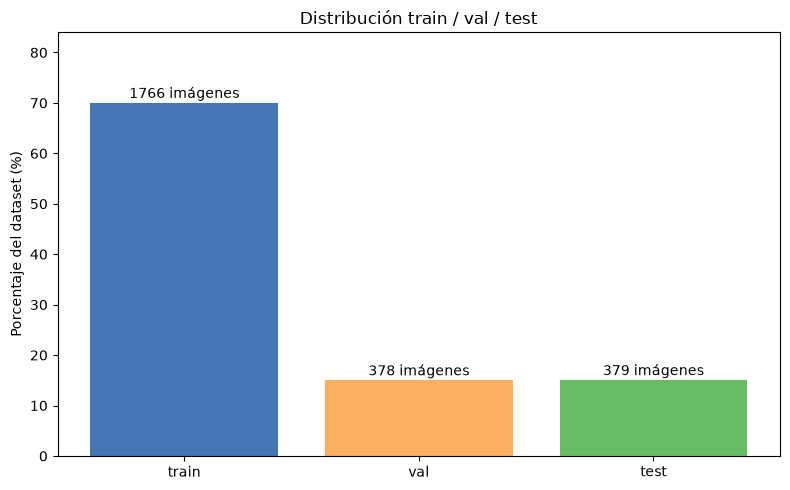

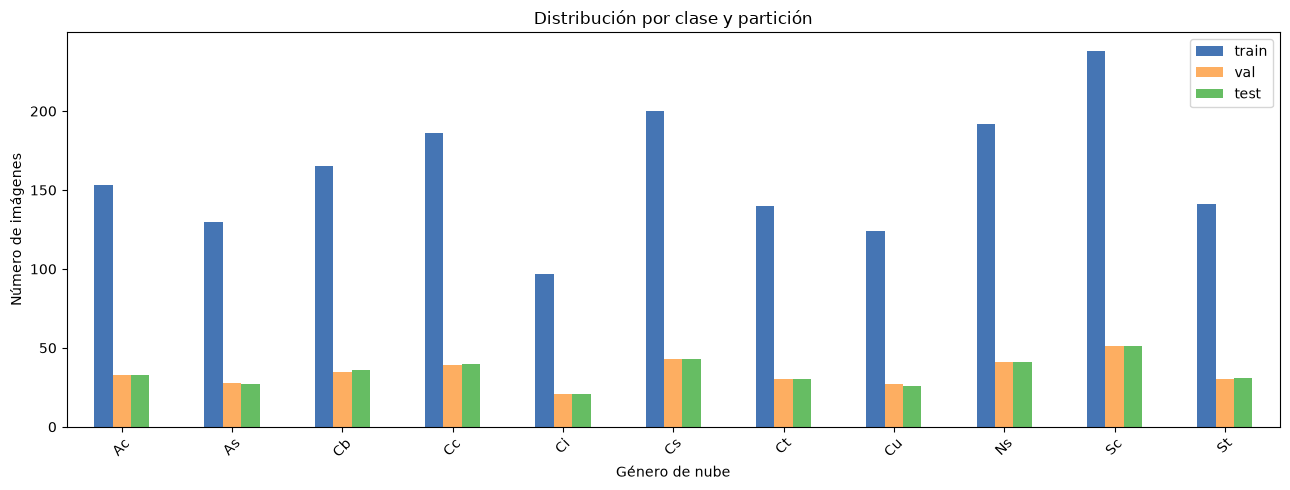

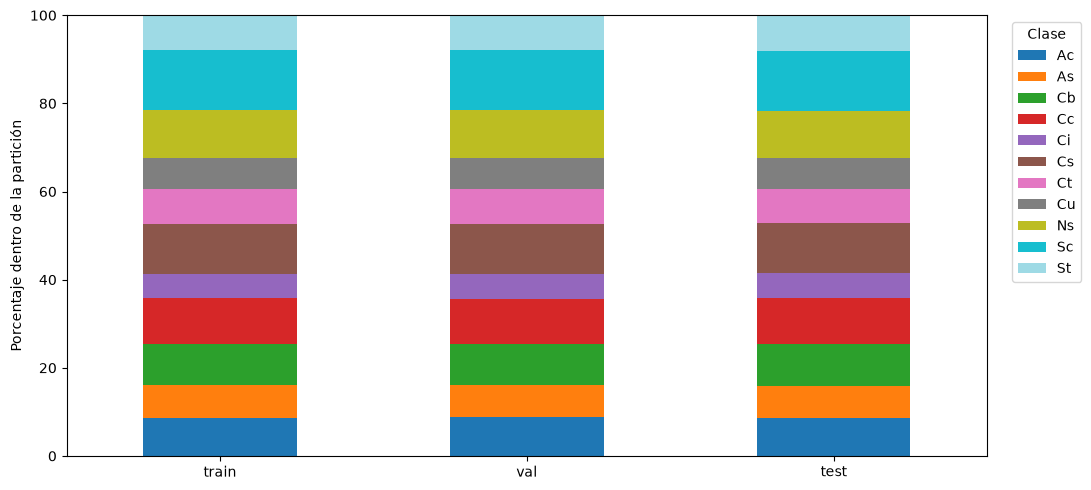

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(
    tabla_particiones["particion"],
    tabla_particiones["porcentaje"],
    color=["#4575b4", "#fdae61", "#66bd63"],
)
for barra, n in zip(barras, tabla_particiones["imagenes"], strict=True):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 1,
            f"{n} imágenes", ha="center")
ax.set_ylim(0, max(tabla_particiones["porcentaje"]) * 1.2)
ax.set_ylabel("Porcentaje del dataset (%)")
ax.set_title("Distribución train / val / test")
fig.tight_layout()
fig.savefig(SALIDA / "distribucion_particiones.png", dpi=180)
plt.show()
plt.close(fig)

ax = tabla_conteos[list(splits)].plot.bar(
    figsize=(13, 5), color=["#4575b4", "#fdae61", "#66bd63"]
)
ax.set_ylabel("Número de imágenes")
ax.set_xlabel("Género de nube")
ax.set_title("Distribución por clase y partición")
ax.tick_params(axis="x", rotation=45)
fig = ax.figure
fig.tight_layout()
fig.savefig(SALIDA / "distribucion_por_clase.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

ax = tabla_proporciones.T.plot.bar(stacked=True, figsize=(11, 5), colormap="tab20")
ax.set_ylim(0, 100)
ax.set_ylabel("Porcentaje dentro de la partición")
ax.legend(title="Clase", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.tick_params(axis="x", rotation=0)
fig = ax.figure
fig.tight_layout()
fig.savefig(SALIDA / "composicion_porcentual.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 4. Primera ejecución del entrenamiento

`run_experiment` entrena durante 15 épocas, selecciona el mejor checkpoint por **menor `val_loss`** y evalúa `train` y `val` con esos pesos. No utiliza `test`. La ejecución requiere las dependencias del proyecto (incluido MLflow) y las imágenes preparadas.

In [6]:
resultado_dropout = run_experiment(config)
print("Checkpoint:", resultado_dropout.checkpoint_path)
print("Mejor época y métricas:", resultado_dropout.final_metrics())

Época   1/15 | train loss 2.1976 acc 0.2220 | val loss 2.1197 acc 0.2751 | 184.1s *
Época   2/15 | train loss 2.0217 acc 0.2860 | val loss 1.9566 acc 0.3175 | 182.2s *
Época   3/15 | train loss 1.9488 acc 0.3126 | val loss 1.8638 acc 0.3466 | 181.3s *
Época   4/15 | train loss 1.8707 acc 0.3375 | val loss 1.8547 acc 0.3360 | 187.2s *
Época   5/15 | train loss 1.8588 acc 0.3539 | val loss 1.8372 acc 0.3492 | 184.0s *
Época   6/15 | train loss 1.8102 acc 0.3720 | val loss 1.8329 acc 0.3307 | 169.3s *
Época   7/15 | train loss 1.7741 acc 0.3805 | val loss 1.8083 acc 0.3624 | 189.0s *
Época   8/15 | train loss 1.7527 acc 0.4009 | val loss 1.7661 acc 0.3889 | 171.4s *
Época   9/15 | train loss 1.7385 acc 0.3958 | val loss 1.8756 acc 0.3439 | 195.3s
Época  10/15 | train loss 1.7084 acc 0.4151 | val loss 1.7652 acc 0.3836 | 211.1s *
Época  11/15 | train loss 1.6794 acc 0.4139 | val loss 1.7615 acc 0.3968 | 195.7s *
Época  12/15 | train loss 1.6751 acc 0.4128 | val loss 1.7565 acc 0.3757 | 194

## 5. Historial, mejor época y curvas

Mejor época (mínimo val_loss): 12
Mejor val_loss: 1.7564831284618883


,epoca,train_loss,val_loss,train_acc,val_acc,lr,tiempo_segundos,mejor_epoca
0,1,2.1976,2.1197,22.20%,27.51%,0.001000,184.121440,False
1,2,2.0217,1.9566,28.60%,31.75%,0.001000,182.187796,False
2,3,1.9488,1.8638,31.26%,34.66%,0.001000,181.329420,False
3,4,1.8707,1.8547,33.75%,33.60%,0.001000,187.191080,False
4,5,1.8588,1.8372,35.39%,34.92%,0.001000,184.022173,False
5,6,1.8102,1.8329,37.20%,33.07%,0.001000,169.258207,False
6,7,1.7741,1.8083,38.05%,36.24%,0.001000,189.019951,False
7,8,1.7527,1.7661,40.09%,38.89%,0.001000,171.447806,False
8,9,1.7385,1.8756,39.58%,34.39%,0.001000,195.321907,False
9,10,1.7084,1.7652,41.51%,38.36%,0.001000,211.122857,False


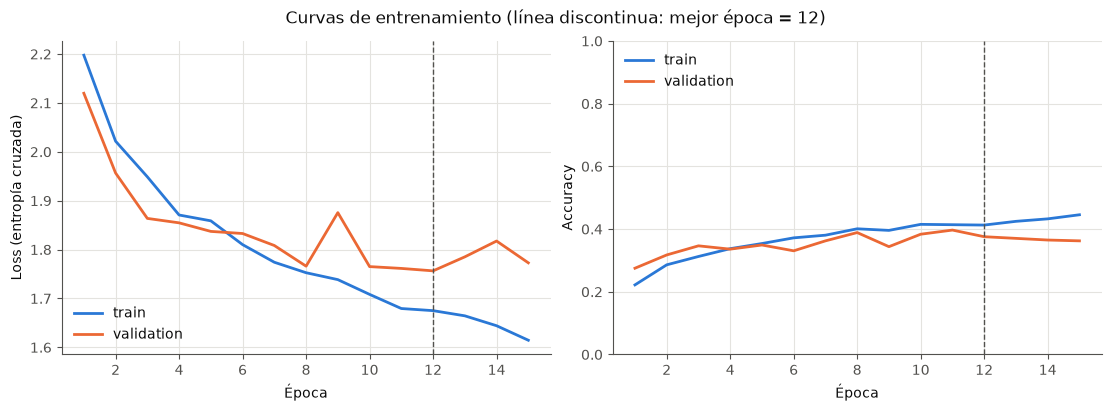

In [7]:
historial = resultado_dropout.history
mejor_epoca = int(historial["best_epoch"])
assert 1 <= mejor_epoca <= len(historial["val_loss"])

tabla_historial = pd.DataFrame({
    "epoca": np.arange(1, len(historial["train_loss"]) + 1),
    "train_loss": historial["train_loss"],
    "val_loss": historial["val_loss"],
    "train_acc": historial["train_acc"],
    "val_acc": historial["val_acc"],
    "lr": historial["lr"],
    "tiempo_segundos": historial["epoch_time"],
})
tabla_historial["mejor_epoca"] = tabla_historial["epoca"].eq(mejor_epoca)
tabla_historial.to_csv(SALIDA / "historial_entrenamiento.csv", index=False)
print("Mejor época (mínimo val_loss):", mejor_epoca)
print("Mejor val_loss:", historial["best_val_loss"])
display(
    tabla_historial.style
    .format({"train_loss": "{:.4f}", "val_loss": "{:.4f}",
             "train_acc": "{:.2%}", "val_acc": "{:.2%}"})
    .background_gradient(cmap="RdYlGn", subset=["train_acc", "val_acc"], vmin=0, vmax=1)
)
fig = plot_training_curves(historial)
fig.savefig(SALIDA / "curvas_entrenamiento.png", dpi=180, bbox_inches="tight")
display(fig)
plt.close(fig)

## 6. Métricas de train y validación con soporte e incertidumbre

`accuracy_clase` corresponde a **recall**: aciertos de la clase divididos por el número real de imágenes de esa clase. Se muestran F1 macro y ponderado; no se modifica artificialmente el accuracy por diferencias de tamaño entre particiones. Los intervalos de Wilson al 95 % son orientativos.

In [8]:
def intervalo_wilson(aciertos, total, z=1.96):
    """Intervalo de Wilson para una proporción binomial."""
    if total == 0:
        return np.nan, np.nan
    p = aciertos / total
    d = 1 + z**2 / total
    c = (p + z**2 / (2 * total)) / d
    m = z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2)) / d
    return c - m, c + m


def tabla_por_clase(evaluacion, nombres):
    """Resume las métricas de cada clase a partir de la evaluación."""
    matriz = np.asarray(evaluacion["confusion_matrix"], dtype=int)
    soporte = matriz.sum(axis=1)
    filas = []
    for i, clase in enumerate(nombres):
        aciertos = int(matriz[i, i])
        inferior, superior = intervalo_wilson(aciertos, int(soporte[i]))
        m = evaluacion["per_class"][clase]
        filas.append({
            "clase": clase, "soporte": int(soporte[i]), "aciertos": aciertos,
            "accuracy_clase": m["recall"], "precision": m["precision"],
            "recall": m["recall"], "f1": m["f1"],
            "ic_inferior": inferior, "ic_superior": superior,
        })
    return pd.DataFrame(filas)


def grafico_accuracy(tabla, nombre, destino):
    """Muestra el recall por clase con barras de incertidumbre."""
    valores = tabla["accuracy_clase"].to_numpy()
    limites = np.vstack([
        np.maximum(valores - tabla["ic_inferior"].to_numpy(), 0),
        np.maximum(tabla["ic_superior"].to_numpy() - valores, 0),
    ]) * 100
    fig, ax = plt.subplots(figsize=(13, 6))
    ax.bar(tabla["clase"], valores * 100, color=plt.get_cmap("RdYlGn")(valores),
           yerr=limites, capsize=3, error_kw={"ecolor": "#333333"})
    ax.set_ylim(0, 105)
    ax.set_ylabel("Accuracy por clase / recall (%)")
    ax.set_title(f"Accuracy por clase e IC de Wilson 95 % — {nombre}")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.2)
    fig.tight_layout()
    fig.savefig(destino, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

Métricas por clase — train


,clase,soporte,aciertos,accuracy_clase,precision,recall,f1,ic_inferior,ic_superior
0,Ac,153,37,24.18%,40.22%,24.18%,30.20%,18.08%,31.55%
1,As,130,47,36.15%,50.00%,36.15%,41.96%,28.40%,44.70%
2,Cb,165,137,83.03%,44.92%,83.03%,58.30%,76.57%,87.99%
3,Cc,186,97,52.15%,57.40%,52.15%,54.65%,45.00%,59.21%
4,Ci,97,22,22.68%,46.81%,22.68%,30.56%,15.48%,31.96%
5,Cs,200,18,9.00%,52.94%,9.00%,15.38%,5.77%,13.78%
6,Ct,140,120,85.71%,53.57%,85.71%,65.93%,78.96%,90.56%
7,Cu,124,37,29.84%,54.41%,29.84%,38.54%,22.49%,38.40%
8,Ns,192,105,54.69%,34.65%,54.69%,42.42%,47.62%,61.57%
9,Sc,238,185,77.73%,44.90%,77.73%,56.92%,72.03%,82.55%


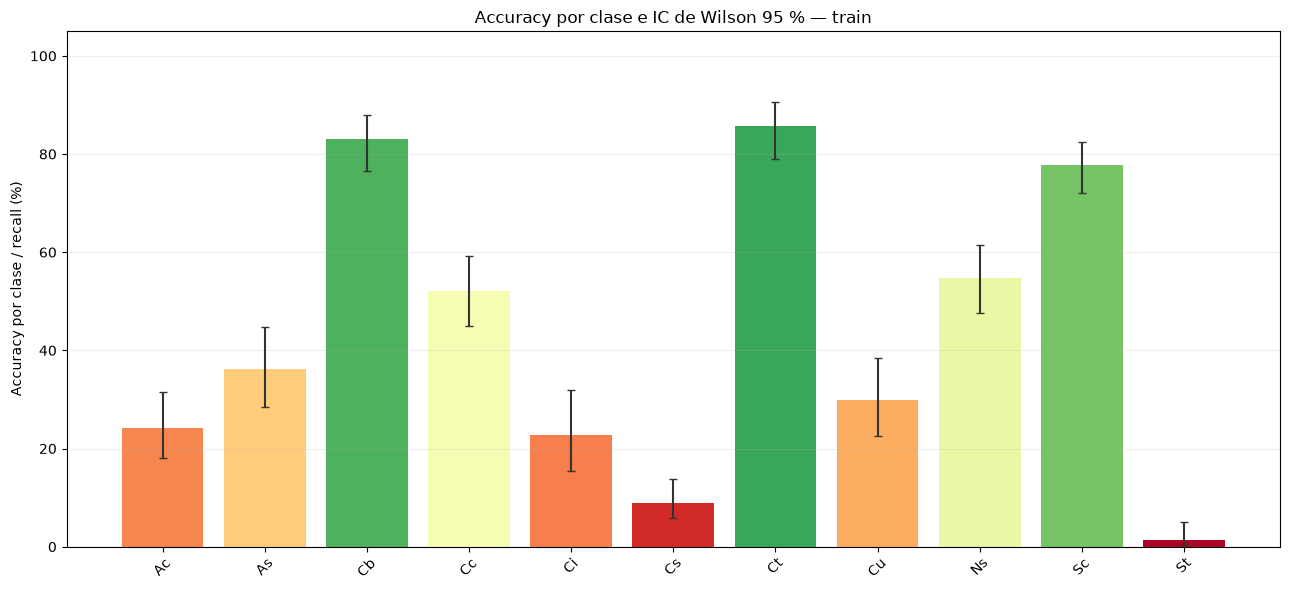

Métricas por clase — val


,clase,soporte,aciertos,accuracy_clase,precision,recall,f1,ic_inferior,ic_superior
0,Ac,33,4,12.12%,23.53%,12.12%,16.00%,4.82%,27.33%
1,As,28,8,28.57%,53.33%,28.57%,37.21%,15.25%,47.06%
2,Cb,35,20,57.14%,27.40%,57.14%,37.04%,40.86%,72.02%
3,Cc,39,18,46.15%,52.94%,46.15%,49.32%,31.57%,61.43%
4,Ci,21,2,9.52%,16.67%,9.52%,12.12%,2.65%,28.91%
5,Cs,43,4,9.30%,28.57%,9.30%,14.04%,3.68%,21.60%
6,Ct,30,21,70.00%,53.85%,70.00%,60.87%,52.12%,83.34%
7,Cu,27,6,22.22%,35.29%,22.22%,27.27%,10.61%,40.76%
8,Ns,41,19,46.34%,30.65%,46.34%,36.89%,32.06%,61.25%
9,Sc,51,39,76.47%,41.94%,76.47%,54.17%,63.24%,86.00%


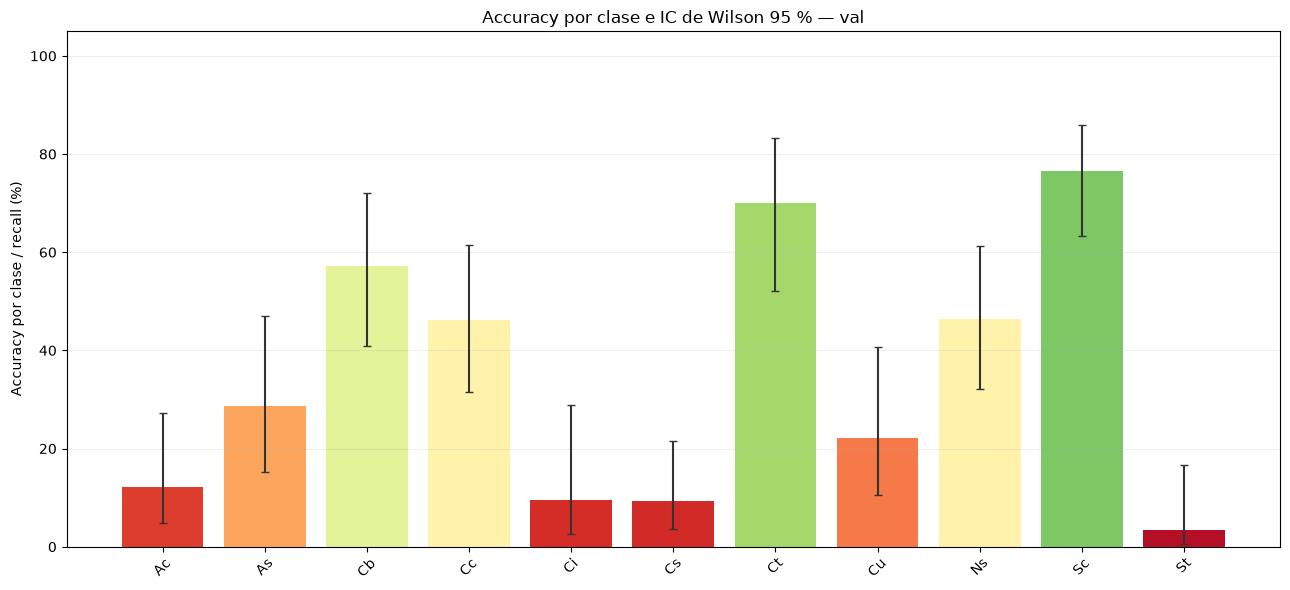

Métricas globales de entrenamiento y validación


,particion,imagenes,aciertos,loss,accuracy,macro_f1,f1_ponderado,ic_inferior,ic_superior
0,train,1766,807,1.5518,45.70%,39.76%,40.75%,43.38%,48.03%
1,val,378,142,1.7565,37.57%,31.92%,33.53%,32.83%,42.55%


In [9]:
clases = list(resultado_dropout.class_names)
assert clases == list(clases_datos)
evaluaciones = {
    "train": resultado_dropout.train_eval.to_dict(clases),
    "val": resultado_dropout.val_eval.to_dict(clases),
}
filas_generales = []
for nombre, evaluacion in evaluaciones.items():
    tabla = tabla_por_clase(evaluacion, clases)
    matriz = np.asarray(evaluacion["confusion_matrix"], dtype=int)
    total = int(matriz.sum())
    aciertos = int(np.trace(matriz))
    assert total == int(totales[nombre])
    ic_inf, ic_sup = intervalo_wilson(aciertos, total)
    f1_ponderado = np.average(tabla["f1"], weights=tabla["soporte"])
    filas_generales.append({
        "particion": nombre, "imagenes": total, "aciertos": aciertos,
        "loss": evaluacion["loss"], "accuracy": evaluacion["accuracy"],
        "macro_f1": evaluacion["macro_f1"],
        "f1_ponderado": f1_ponderado,
        "ic_inferior": ic_inf, "ic_superior": ic_sup,
    })
    tabla.to_csv(SALIDA / f"metricas_por_clase_{nombre}.csv", index=False)
    print(f"Métricas por clase — {nombre}")
    display(
        tabla.style.format({
            "accuracy_clase": "{:.2%}", "precision": "{:.2%}",
            "recall": "{:.2%}", "f1": "{:.2%}",
            "ic_inferior": "{:.2%}", "ic_superior": "{:.2%}",
        })
        .background_gradient(cmap="RdYlGn", subset=[
            "accuracy_clase", "precision", "recall", "f1"
        ], vmin=0, vmax=1)
        .background_gradient(cmap="Blues", subset=["soporte"])
    )
    grafico_accuracy(tabla, nombre, SALIDA / f"accuracy_por_clase_{nombre}.png")

tabla_general = pd.DataFrame(filas_generales)
tabla_general.to_csv(SALIDA / "metricas_generales.csv", index=False)
print("Métricas globales de entrenamiento y validación")
display(
    tabla_general.style.format({
        "loss": "{:.4f}", "accuracy": "{:.2%}", "macro_f1": "{:.2%}",
        "f1_ponderado": "{:.2%}", "ic_inferior": "{:.2%}",
        "ic_superior": "{:.2%}",
    }).background_gradient(cmap="RdYlGn", subset=[
        "accuracy", "macro_f1", "f1_ponderado"
    ], vmin=0, vmax=1)
)

## 7. Matrices de confusión coloreadas

**Filas = clase real; columnas = predicción.** Cada celda contiene el número de imágenes y el porcentaje respecto a su fila. Verde en la diagonal indica aciertos; rojo fuera de ella indica confusiones. Se guardan matrices absolutas y normalizadas.

Matriz absoluta — train


,Ac,As,Cb,Cc,Ci,Cs,Ct,Cu,Ns,Sc,St
clase_real,,,,,,,,,,,
Ac,37,11,16,21,2,2,14,11,24,11,4
As,8,47,23,3,1,1,9,0,24,12,2
Cb,1,4,137,0,0,0,0,0,7,16,0
Cc,19,3,3,97,12,4,19,5,12,9,3
Ci,3,2,7,12,22,2,25,3,9,12,0
Cs,8,9,14,21,7,18,23,3,46,47,4
Ct,0,1,5,3,0,1,120,5,3,1,1
Cu,3,4,49,1,0,0,3,37,13,14,0
Ns,6,5,17,3,2,2,6,2,105,43,1


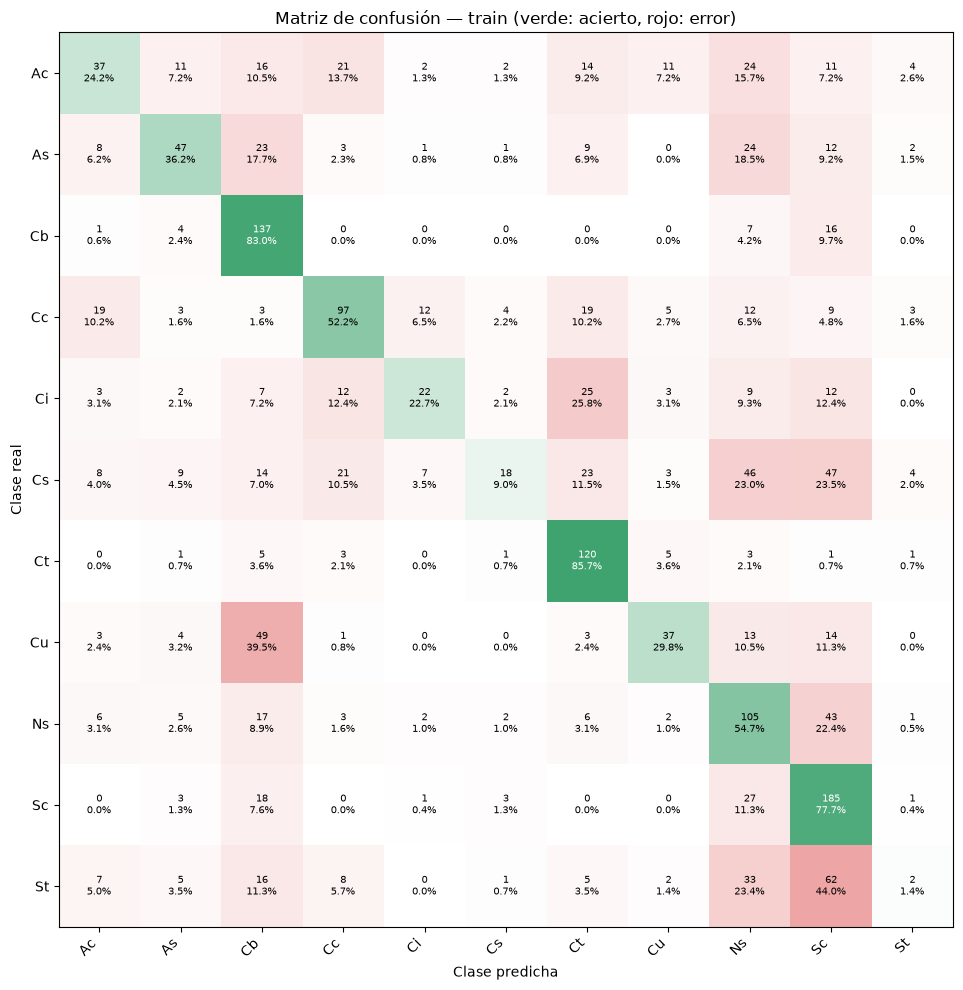

Matriz absoluta — val


,Ac,As,Cb,Cc,Ci,Cs,Ct,Cu,Ns,Sc,St
clase_real,,,,,,,,,,,
Ac,4,1,5,7,2,2,1,2,4,4,1
As,0,8,6,1,2,1,3,1,2,4,0
Cb,1,0,20,0,0,0,0,3,6,5,0
Cc,6,1,2,18,1,1,3,1,3,3,0
Ci,1,1,3,2,2,3,4,0,3,2,0
Cs,3,0,6,5,1,4,5,3,10,6,0
Ct,0,4,0,0,4,0,21,0,1,0,0
Cu,2,0,15,0,0,0,1,6,2,1,0
Ns,0,0,5,1,0,0,1,0,19,15,0


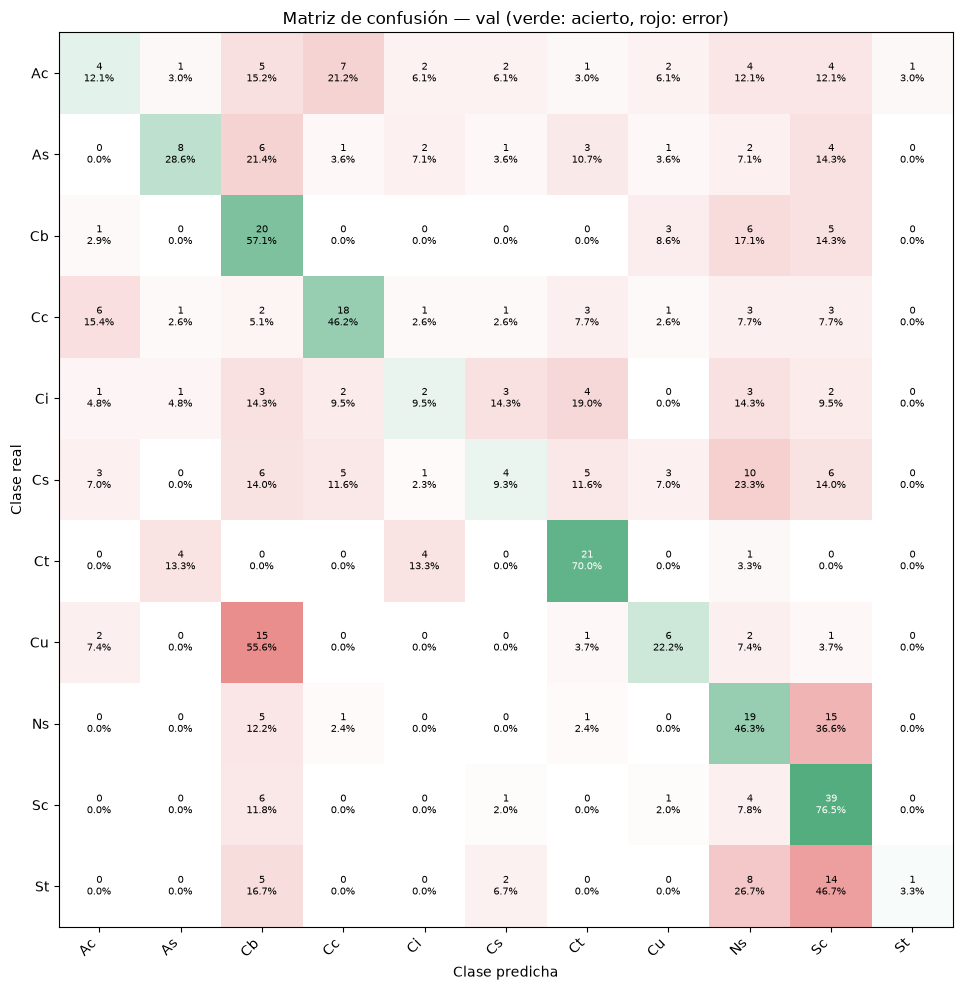

In [10]:
def graficar_confusion(matriz, nombres, particion, destino):
    """Matriz con aciertos verdes y errores rojos, normalizada por fila."""
    total_fila = matriz.sum(axis=1, keepdims=True)
    normalizada = np.divide(matriz, total_fila,
                            out=np.zeros_like(matriz, dtype=float),
                            where=total_fila != 0)
    colores = np.ones((*matriz.shape, 3), dtype=float)
    for i in range(len(nombres)):
        for j in range(len(nombres)):
            base = np.array([0.12, 0.58, 0.34] if i == j else [0.85, 0.20, 0.20])
            colores[i, j] = (1 - normalizada[i, j]) + normalizada[i, j] * base
    fig, ax = plt.subplots(figsize=(13, 10))
    ax.imshow(colores)
    ax.set_xticks(range(len(nombres)), nombres, rotation=45, ha="right")
    ax.set_yticks(range(len(nombres)), nombres)
    for i in range(len(nombres)):
        for j in range(len(nombres)):
            p = normalizada[i, j]
            ax.text(j, i, f"{matriz[i, j]}\n{p:.1%}", ha="center", va="center",
                    fontsize=7, color="white" if p >= 0.65 else "black")
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(f"Matriz de confusión — {particion} (verde: acierto, rojo: error)")
    fig.tight_layout()
    fig.savefig(destino, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return normalizada


for nombre, evaluacion in evaluaciones.items():
    matriz = np.asarray(evaluacion["confusion_matrix"], dtype=int)
    assert matriz.shape == (len(clases), len(clases))
    tabla_matriz = pd.DataFrame(matriz, index=clases, columns=clases)
    tabla_matriz.index.name = "clase_real"
    tabla_matriz.to_csv(SALIDA / f"matriz_confusion_{nombre}.csv")
    print(f"Matriz absoluta — {nombre}")
    display(tabla_matriz.style.background_gradient(cmap="Blues", axis=None))
    normalizada = graficar_confusion(
        matriz, clases, nombre, SALIDA / f"matriz_confusion_{nombre}.png"
    )
    pd.DataFrame(normalizada, index=clases, columns=clases).to_csv(
        SALIDA / f"matriz_normalizada_{nombre}.csv"
    )

## 8. Resumen y comparación de train / val

La diferencia entre train y val sirve para analizar generalización; la incertidumbre de validación depende de su número de imágenes. No se compara con `test` aquí.

,experimento,dropout_p,batchnorm,batch_size,epocas_entrenadas,mejor_epoca,mejor_val_loss,train_accuracy_eval,val_accuracy_eval,generalization_gap
0,droput_03,0.3,True,64,15,12,1.7565,0.457,0.3757,0.0813


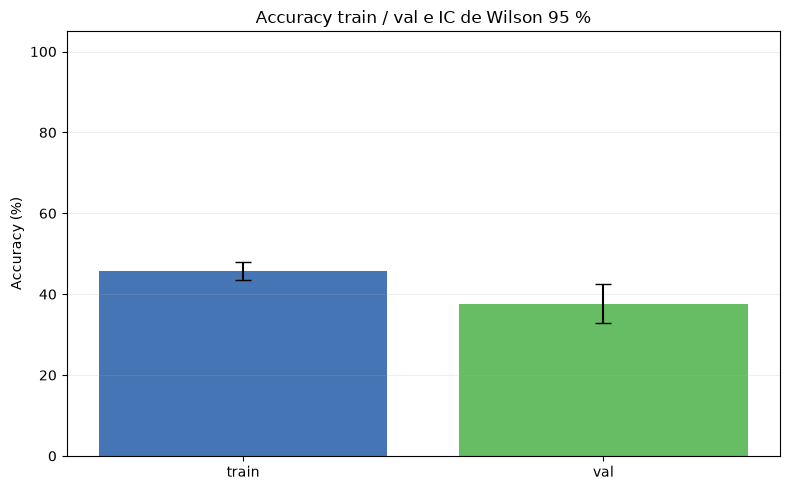

Métricas y figuras guardadas en: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\outputs\metricas\droput_03


In [11]:
resumen = pd.DataFrame([{
    "experimento": config.run_name,
    "dropout_p": config.dropout_p,
    "batchnorm": config.use_batchnorm,
    "batch_size": config.batch_size,
    "epocas_entrenadas": len(historial["train_loss"]),
    "mejor_epoca": mejor_epoca,
    "mejor_val_loss": historial["best_val_loss"],
    "train_accuracy_eval": evaluaciones["train"]["accuracy"],
    "val_accuracy_eval": evaluaciones["val"]["accuracy"],
    "generalization_gap": resultado_dropout.generalization_gap,
}])
resumen.to_csv(SALIDA / "resumen_experimento.csv", index=False)
display(resumen.round(4))

valores = tabla_general["accuracy"].to_numpy()
err = np.vstack([
    valores - tabla_general["ic_inferior"].to_numpy(),
    tabla_general["ic_superior"].to_numpy() - valores,
]) * 100
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(tabla_general["particion"], valores * 100,
       color=["#4575b4", "#66bd63"], yerr=err, capsize=6)
ax.set_ylim(0, 105)
ax.set_ylabel("Accuracy (%)")
ax.set_title("Accuracy train / val e IC de Wilson 95 %")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(SALIDA / "comparacion_accuracy.png", dpi=180)
plt.show()
plt.close(fig)
print("Métricas y figuras guardadas en:", SALIDA)

## 9. Visualización de una imagen y feature maps del mejor checkpoint

Se utiliza una imagen de **validación** y los pesos de la mejor época. `capture_feature_maps` registra temporalmente un hook en una capa, sin modificar la red.

Clase real: Ac | Predicción: Ac


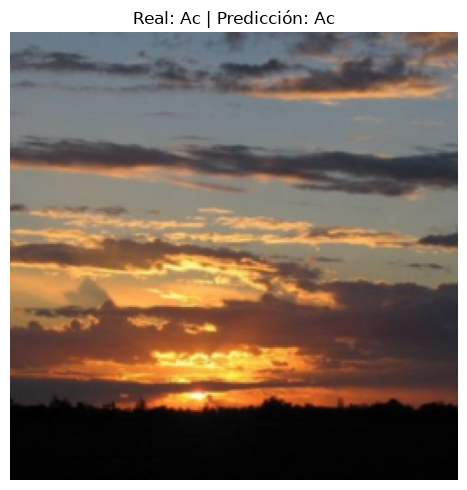

In [12]:
device = torch.device("cpu")
modelo_dropout = build_model(config).to(device)
checkpoint = torch.load(resultado_dropout.checkpoint_path,
                        map_location=device, weights_only=True)
modelo_dropout.load_state_dict(checkpoint["model_state_dict"])
modelo_dropout.eval()

loader_val = make_split_loader(config, "val")
imagenes, etiquetas = next(iter(loader_val))
imagen = imagenes[:1]
clase_real = clases[int(etiquetas[0])]
with torch.inference_mode():
    logits = modelo_dropout(imagen.to(device))
prediccion = clases[int(logits.argmax(dim=1).item())]
print("Clase real:", clase_real, "| Predicción:", prediccion)

imagen_rgb = denormalize(imagen[0], stats["mean_train"], stats["std_train"])
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(imagen_rgb.permute(1, 2, 0).numpy())
ax.set_title(f"Real: {clase_real} | Predicción: {prediccion}")
ax.axis("off")
fig.tight_layout()
fig.savefig(SALIDA / "ejemplo_validacion.png", dpi=180)
plt.show()
plt.close(fig)

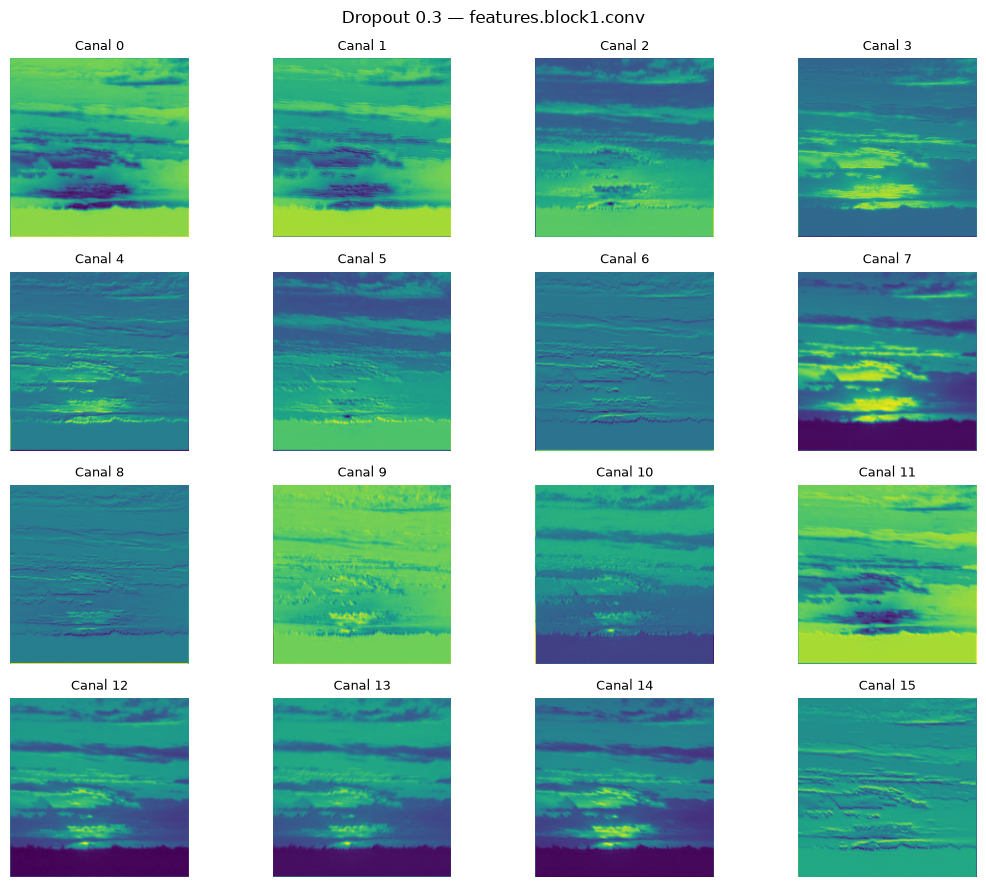

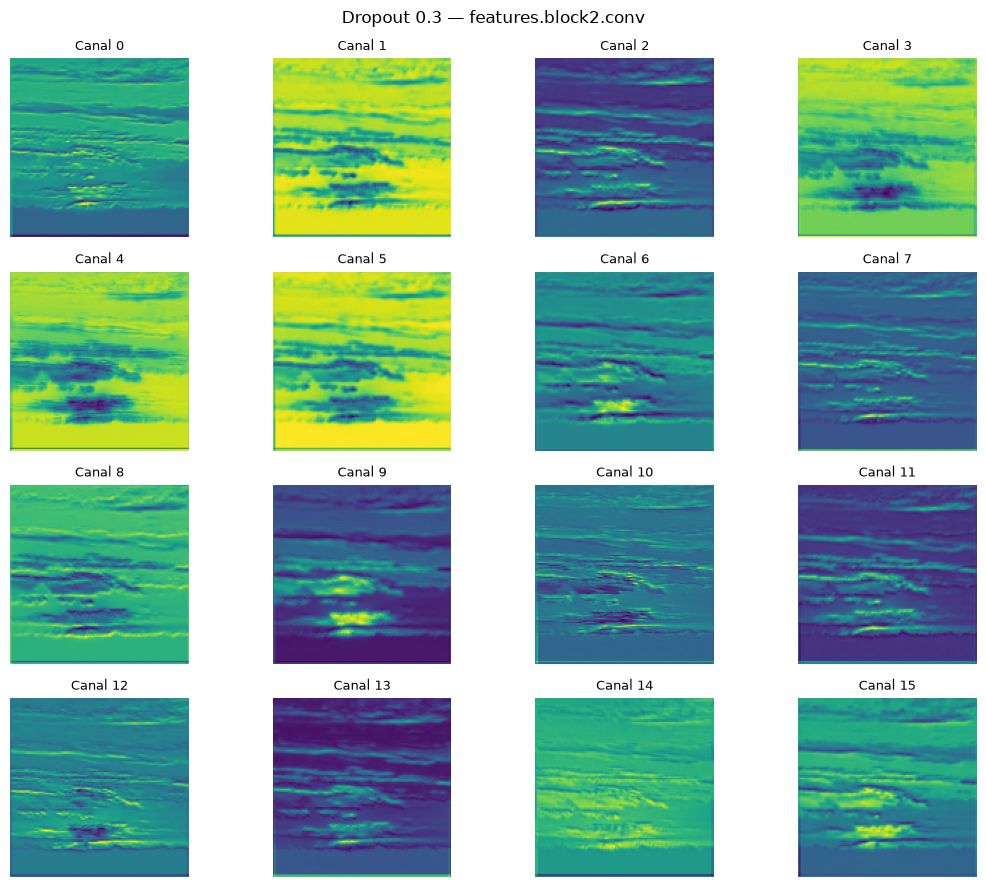

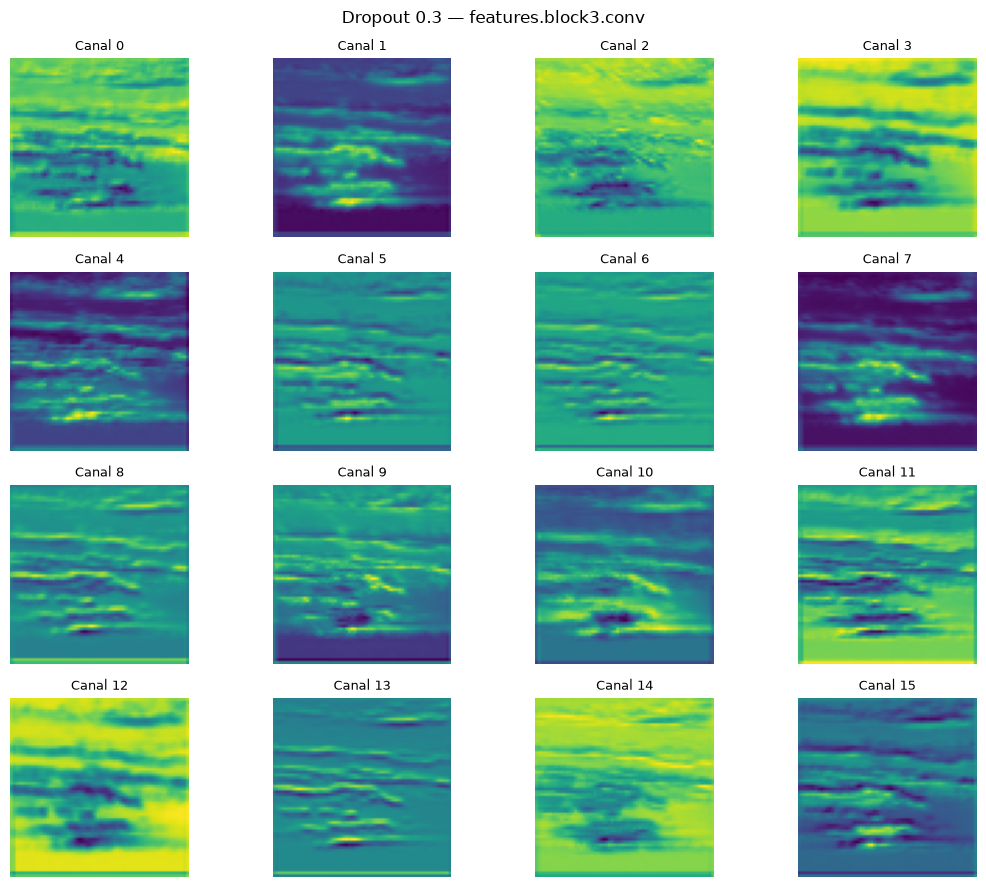

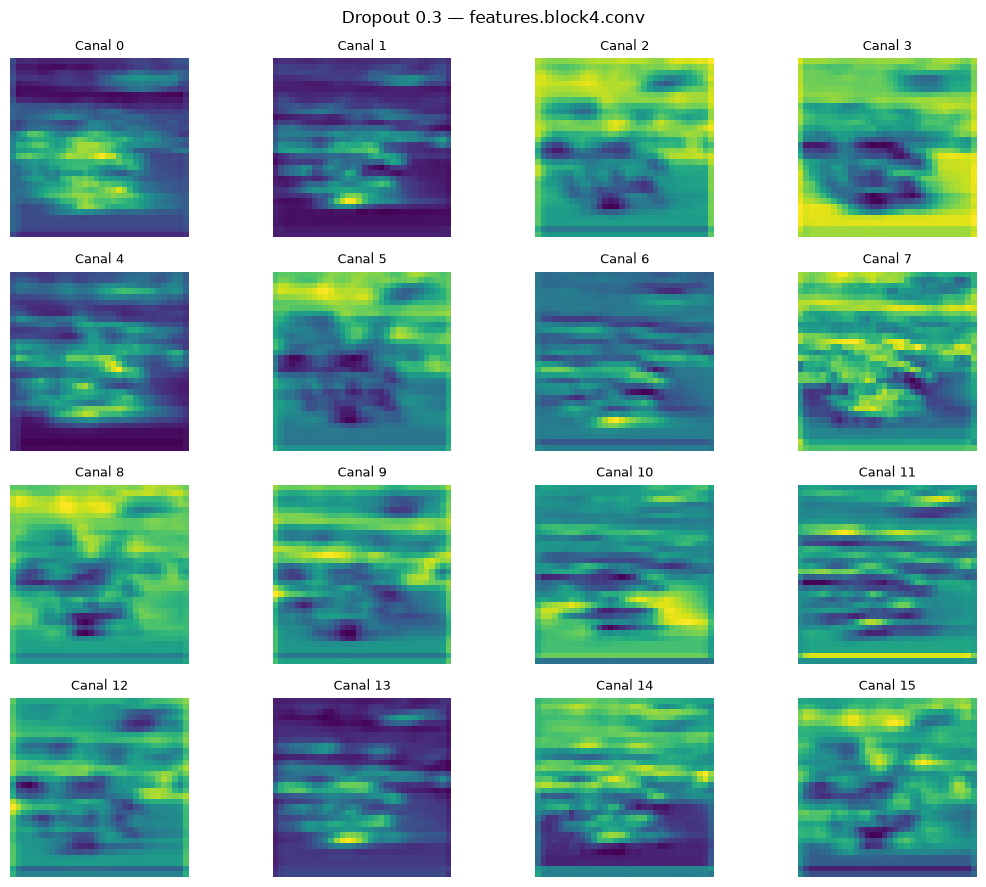

Feature maps guardados en: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\outputs\feature_maps\droput_03


In [13]:
capas = [
    nombre for nombre, modulo in modelo_dropout.named_modules()
    if nombre and isinstance(modulo, torch.nn.Conv2d)
]
assert capas, "No se encontraron capas convolucionales."
SALIDA_MAPAS = config.output_root / "feature_maps" / config.run_name
SALIDA_MAPAS.mkdir(parents=True, exist_ok=True)

for nombre in capas:
    with torch.inference_mode():
        activacion = capture_feature_maps(modelo_dropout, imagen, nombre, device)
    mapas = activacion[0].detach().cpu()
    assert mapas.ndim == 3
    cantidad = min(16, mapas.shape[0])
    fig, axes = plt.subplots(4, 4, figsize=(11, 9))
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < cantidad:
            ax.imshow(mapas[i].numpy(), cmap="viridis")
            ax.set_title(f"Canal {i}", fontsize=9)
    fig.suptitle(f"Dropout 0.3 — {nombre}")
    fig.tight_layout()
    archivo = SALIDA_MAPAS / f"{nombre.replace('.', '_')}.png"
    fig.savefig(archivo, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Feature maps guardados en:", SALIDA_MAPAS)